# exp04: Representasi Fitur

Membandingkan original, clean, penggabungan EAR, HRV absolut, rasio HRV, serta transformasi log HRV. Clean menghapus blink_count, iris_size_delta_std, dan eye_state_other_ratio. Logistic Regression juga membandingkan StandardScaler dengan RobustScaler. Tidak ada tuning parameter model.

Dataset: good_acceptable, window 45 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp04"
WINDOW = "window_45s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_45s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,614
1,Medium,650
2,High,854


,id,model,scaler,tune,variant,candidate_count
0,xgboost_original,xgboost,NaN,False,original,1
1,xgboost_clean,xgboost,NaN,False,clean,1
2,xgboost_ear,xgboost,NaN,False,ear,1
3,xgboost_absolute,xgboost,NaN,False,absolute,1
4,xgboost_ratio,xgboost,NaN,False,ratio,1
5,xgboost_log,xgboost,NaN,False,log,1
6,logistic_original,logistic,standard,False,original,1
7,logistic_clean,logistic,standard,False,clean,1
8,logistic_ear,logistic,standard,False,ear,1
9,logistic_absolute,logistic,standard,False,absolute,1


2118 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,1880,238,3
1,fold_01,Andreas,2035,83,3
2,fold_02,Athaya,1979,139,3
3,fold_03,Fabian,1902,216,3
4,fold_04,Rafi,1863,255,3
5,fold_05,Savitri,1916,202,3
6,fold_06,Shakilla,2054,64,3
7,fold_07,Tio,1943,175,3
8,fold_08,faqih,1900,218,3
9,fold_09,ikhsan,1906,212,3


Complete run verified: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_45s_step_5s\full_f7bea090bac3


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_45s_step_5s\full_f7bea090bac3


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
0,logistic_absolute,0.359301,0.365697,0.359398,2118
6,logistic_ratio,0.323890,0.330384,0.320067,2118
7,xgboost_absolute,0.316336,0.326884,0.317969,2118
1,logistic_clean,0.323418,0.330043,0.314725,2118
4,logistic_log,0.323418,0.327539,0.314684,2118
5,logistic_original,0.322946,0.329500,0.314320,2118
2,logistic_clean_robust,0.320585,0.326936,0.311273,2118
9,xgboost_ear,0.297923,0.303955,0.298451,2118
3,logistic_ear,0.302644,0.305865,0.289117,2118
8,xgboost_clean,0.278565,0.284505,0.279679,2118


,scope,model,label,precision,recall,f1,support
0,pooled,logistic_absolute,Low,0.312933,0.441368,0.366216,614
1,pooled,logistic_absolute,Medium,0.378608,0.343077,0.359968,650
2,pooled,logistic_absolute,High,0.402715,0.312646,0.352011,854
42,pooled,logistic_clean,Low,0.291467,0.495114,0.366928,614
43,pooled,logistic_clean,Medium,0.291028,0.204615,0.240289,650
44,pooled,logistic_clean,High,0.401294,0.290398,0.336957,854
84,pooled,logistic_clean_robust,Low,0.291627,0.493485,0.366606,614
85,pooled,logistic_clean_robust,Medium,0.283186,0.196923,0.232305,650
86,pooled,logistic_clean_robust,High,0.395534,0.290398,0.334909,854
126,pooled,logistic_ear,Low,0.288442,0.467427,0.356743,614


accuracy                     balanced_accuracy  \
                            min    median       max               min   
model                                                                   
logistic_absolute      0.122302  0.388889  0.545098          0.162545   
logistic_clean         0.037736  0.330435  0.859375          0.033613   
logistic_clean_robust  0.037736  0.286957  0.734375          0.033613   
logistic_ear           0.000000  0.278261  0.504630          0.000000   
logistic_log           0.009434  0.278261  0.921875          0.008403   
logistic_original      0.037736  0.330435  0.859375          0.033613   
logistic_ratio         0.000000  0.365741  0.875000          0.000000   
xgboost_absolute       0.000000  0.313253  0.439216          0.000000   
xgboost_clean          0.000000  0.292079  0.478431          0.000000   
xgboost_ear            0.000000  0.282178  0.513725          0.000000   
xgboost_log            0.000000  0.292079  0.478431          0.000000   
xgboost_original       0.000000  0.292079  0.486275          0.000000   
xgboost_ratio          0.004717  0.260504  0.474510          0.005376   

                                           macro_f1                      
                         median       max       min    median       max  
model                                                                    
logistic_absolute      0.333333  0.528080  0.142623  0.240358  0.680412  
logistic_clean         0.333333  0.859375  0.061538  0.202886  0.924370  
logistic_clean_robust  0.333333  0.734375  0.061538  0.205027  0.846847  
logistic_ear           0.333333  0.464971  0.000000  0.166100  0.400761  
logistic_log           0.333333  0.921875  0.016529  0.204285  0.959350  
logistic_original      0.333333  0.859375  0.061538  0.199895  0.924370  
logistic_ratio         0.328265  0.875000  0.000000  0.254967  0.933333  
xgboost_absolute       0.328096  0.465876  0.000000  0.254902  0.428811  
xgboost_clean          0.327760  0.433202  0.000000  0.223529  0.338532  
xgboost_ear            0.340451  0.409580  0.000000  0.242623  0.381974  
xgboost_log            0.327760  0.433202  0.000000  0.223529  0.338532  
xgboost_original       0.327760  0.433202  0.000000  0.223529  0.340516  
xgboost_ratio          0.336232  0.474929  0.009901  0.172418  0.400938

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

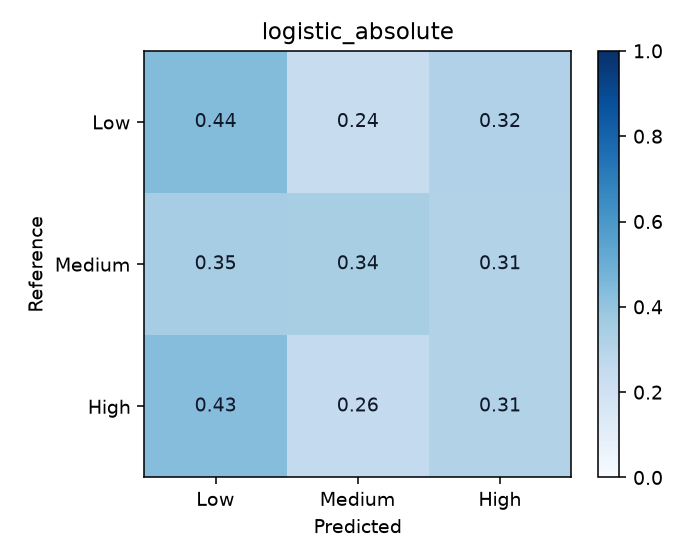

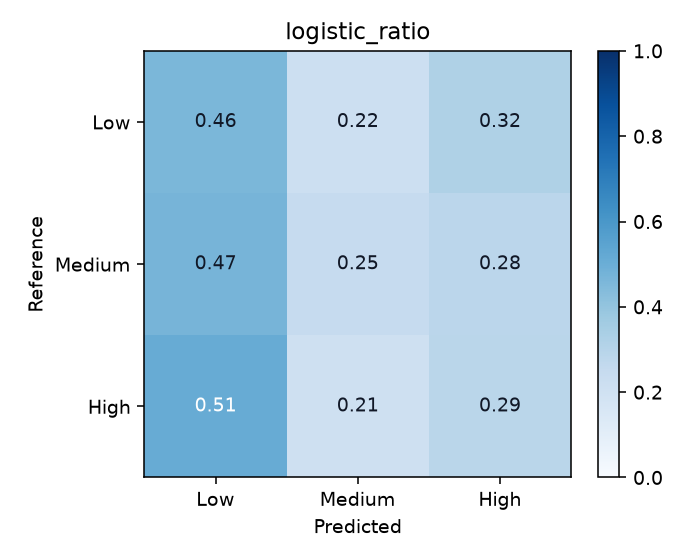

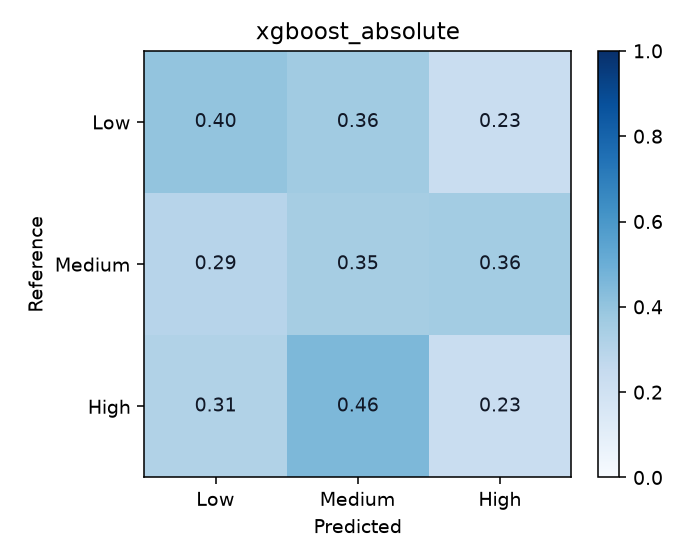

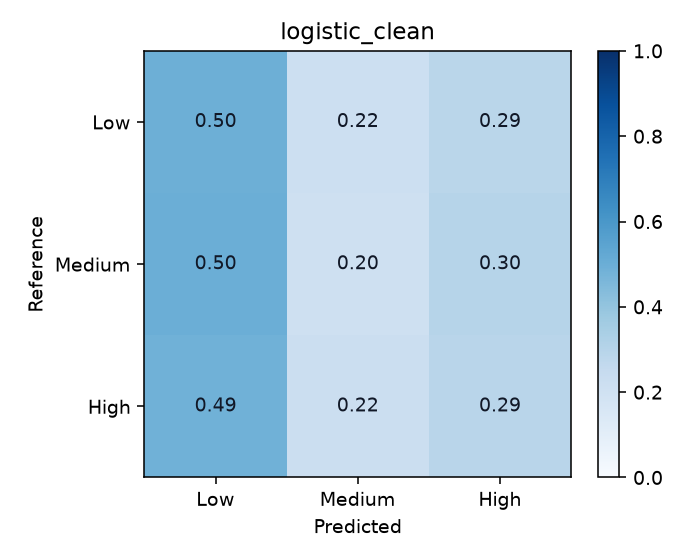

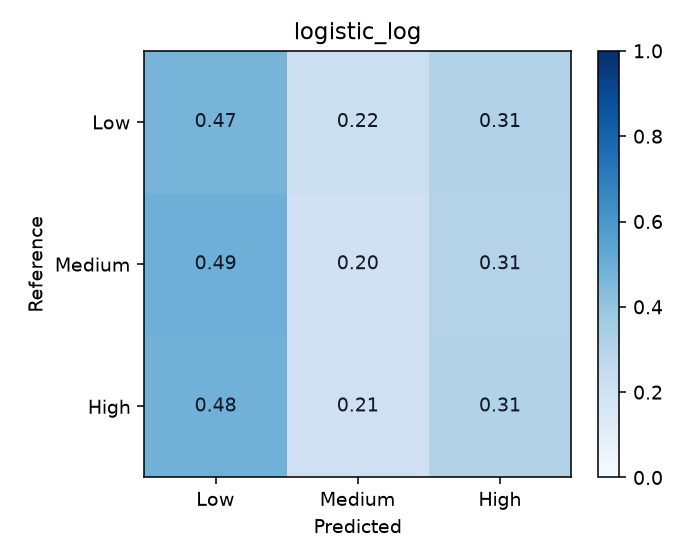

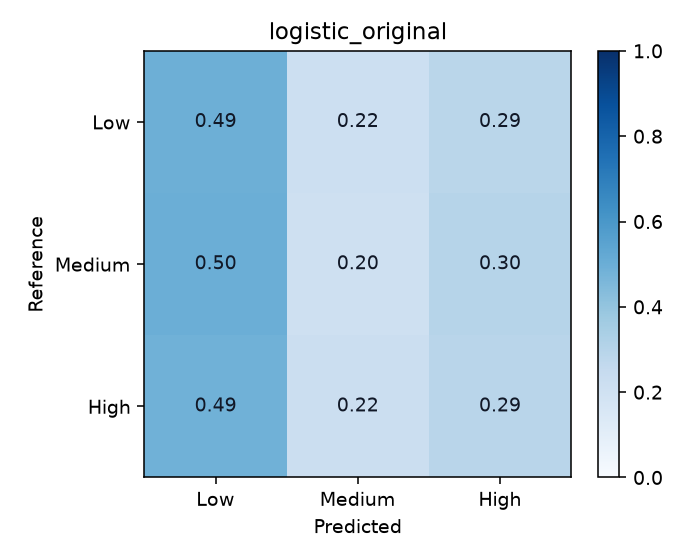

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_45s_step_5s\full_f7bea090bac3
